# 02 · TP2: forecasting next month's regional demand

Course protocol, reproduced exactly from the raw file:

- **Train** Jan 2018 – Aug 2019 (180 region-months), **test** Sep 2019 – Feb 2020 (54).
- **Validation** inside train: 4 consecutive blocks of 3 months.
- **Pre-registered**: model (Ridge, α = 3.16), metric (RMSE) and goal (10 % less RMSE than the seasonal rule *same month last year*) were fixed before the test was opened.
- The other models' hyperparameters come from a grid search done *after* the formal evaluation (reported as post-hoc).

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cammesa.plots import style, BLUE, ORANGE, AQUA, YELLOW, RULE, INK2, MUTED
style(); pd.set_option('display.precision', 1); pd.set_option('display.width', 160)
FIG = '../docs/figures/'

In [2]:
from cammesa.data import load_raw, regional_series
from cammesa.features import add_lags
from cammesa import regression
out = regression.run(add_lags(regional_series(load_raw())), verbose=False)
m = out['tp2_metricas'].set_index('modelo')
m[['RMSE validación (GWh)', 'RMSE entrenamiento (GWh)', 'RMSE (GWh)', 'MAPE (%)']].sort_values('RMSE (GWh)').rename(columns={'RMSE (GWh)': 'RMSE test (GWh)'})

,RMSE validación (GWh),RMSE entrenamiento (GWh),RMSE test (GWh),MAPE (%)
modelo,,,,
Bosque aleatorio,134.4,116.3,67.8,4.7
Regla: mismo mes del año anterior,128.4,118.3,71.0,4.5
Regresión lineal,119.6,94.8,71.4,4.3
Ridge (pre-registrado),103.7,101.9,76.7,4.5
Elastic Net,99.3,109.9,93.9,5.0
Lasso,96.9,111.4,96.6,5.0
Regla: media de la región,209.6,187.2,128.7,8.2
Regla: mes anterior,170.6,167.2,146.2,7.8
Gradient boosting,93.4,118.1,169.0,6.1


In [3]:
ridge, rule = m.loc['Ridge (pre-registrado)', 'RMSE (GWh)'], m.loc[regression.SEASONAL_RULE, 'RMSE (GWh)']
print(f'Ridge {ridge:.1f} GWh vs rule {rule:.1f} GWh -> goal {0.9 * rule:.1f} GWh: not met')

Ridge 76.7 GWh vs rule 71.0 GWh -> goal 63.9 GWh: not met


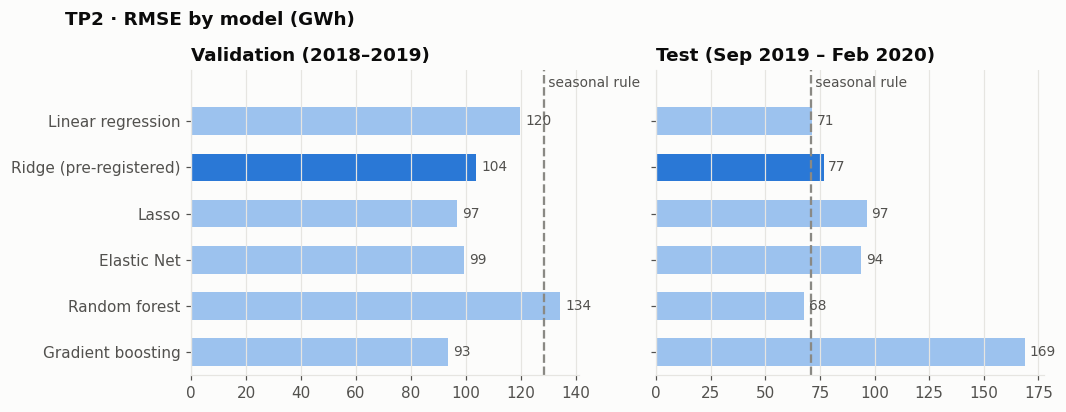

In [4]:
models = [n for n in m.index if not n.startswith('Regla')]
EN = {'Regresión lineal': 'Linear regression', 'Ridge (pre-registrado)': 'Ridge (pre-registered)', 'Lasso': 'Lasso',
      'Elastic Net': 'Elastic Net', 'Bosque aleatorio': 'Random forest', 'Gradient boosting': 'Gradient boosting'}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, col, title in [(axes[0], 'RMSE validación (GWh)', 'Validation (2018–2019)'), (axes[1], 'RMSE (GWh)', 'Test (Sep 2019 – Feb 2020)')]:
    v = m.loc[models, col]
    ax.barh(range(len(v)), v.values, color=[BLUE if 'Ridge' in n else '#9cc2ee' for n in v.index], height=0.6)
    ax.axvline(m.loc[regression.SEASONAL_RULE, col], color=RULE, ls='--', lw=1.5)
    ax.text(m.loc[regression.SEASONAL_RULE, col], -0.75, ' seasonal rule', color=INK2, fontsize=9)
    ax.set_yticks(range(len(v)), [EN[n] for n in v.index]); ax.set_title(title); ax.grid(axis='x'); ax.grid(axis='y', visible=False)
    for i, val in enumerate(v.values): ax.text(val + 2, i, f'{val:.0f}', va='center', fontsize=9, color=INK2)
axes[0].set_ylim(5.5, -1.1); fig.suptitle('TP2 · RMSE by model (GWh)', x=0.01, y=1.03, ha='left', fontweight='bold')
fig.savefig(FIG + 'fig03_tp2.png'); plt.show()

In [5]:
from scipy.stats import spearmanr
r = spearmanr(m.loc[models, 'RMSE validación (GWh)'], m.loc[models, 'RMSE (GWh)']).statistic
print(f'Rank correlation between validation and test among the 6 models: {r:.2f}')

Rank correlation between validation and test among the 6 models: -1.00


**Takeaways**

1. No model beats the seasonal rule on the test months; the pre-registered Ridge is 8 % worse.
2. The validation ranking is exactly reversed on the test (rank correlation −1): the best model in validation (gradient boosting) is the worst on the test. Training covered a falling market and the test a recovering one, so history alone could not tell the models what was coming.
3. That points to missing information rather than a missing algorithm — the question notebooks 05 and 06 pick up.